# FX Time Range Breakout

This notebook uses the original 28-pair study to show how the Python analysis checks range timings and measures profitable-setting coverage.

## Load the study inputs

The archive contains one metadata row per scan and one results row per tested configuration. Read both CSVs directly from the ZIP. In the results, `\N` represents a missing value.

In [1]:
from pathlib import Path
from zipfile import ZipFile

import pandas as pd

archive_path = Path("data") / "TRB06_SL100_inputs.zip"
with ZipFile(archive_path) as archive:
    with archive.open("TRB06_SL100_scans.csv") as file:
        scans = pd.read_csv(file)
    with archive.open("TRB06_SL100_results.csv") as file:
        results = pd.read_csv(file, na_values=[r"\N"])

assert len(scans) == 28, "Unexpected scan count"
assert len(results) == 318_136, "Unexpected result count"
print(f"Scans: {len(scans):,}")
print(f"Configurations: {len(results):,}")

Scans: 28
Configurations: 318,136


In [2]:
results["minutes_after_range"] = results["range_close_min"] - (
    results["range_start_min"] + results["range_duration_min"]
)
results["timing_valid"] = results["minutes_after_range"] >= 120

results["timing_valid"].value_counts().rename(
    index={True: "Valid", False: "Invalid"}
)

timing_valid
Valid      286832
Invalid     31304
Name: count, dtype: int64

In [3]:
backtests = results.merge(
    scans[["source_sha256", "pair_code"]],
    on="source_sha256",
    how="left",
    validate="many_to_one",
)

assert backtests["pair_code"].notna().all(), "A result has no matching scan"
print(f"Configurations: {len(backtests):,}")
print(f"Currency pairs: {backtests['pair_code'].nunique()}")

Configurations: 318,136
Currency pairs: 28


In [4]:
eligible = backtests.loc[
    backtests["timing_valid"] & backtests["trade_count"].gt(0)
].copy()

eligible["profitable"] = eligible["net_profit"].gt(0)

print(f"Eligible settings: {len(eligible):,}")
print(f"Profitable settings: {eligible['profitable'].sum():,}")
print(f"Profitable-setting coverage: {eligible['profitable'].mean():.2%}")

Eligible settings: 286,832
Profitable settings: 49,920
Profitable-setting coverage: 17.40%


In [5]:
pair_coverage = eligible.groupby("pair_code", as_index=False).agg(
    eligible_settings=("profitable", "size"),
    profitable_settings=("profitable", "sum"),
)

pair_coverage["profitable_pct"] = (
    100 * pair_coverage["profitable_settings"] / pair_coverage["eligible_settings"]
)

pair_coverage.sort_values("profitable_pct", ascending=False).head().round(2)

,pair_code,eligible_settings,profitable_settings,profitable_pct
27,USDJPY,10244,9779,95.46
6,CADJPY,10244,8621,84.16
18,GBPJPY,10244,6530,63.74
12,EURJPY,10244,5871,57.31
2,AUDJPY,10244,5036,49.16


In [6]:
pair_codes = pair_coverage["pair_code"]
is_jpy = pair_codes.str.startswith("JPY") | pair_codes.str.endswith("JPY")
pair_coverage["pair_group"] = is_jpy.map({True: "JPY", False: "Non-JPY"})

group_summary = pair_coverage.groupby("pair_group").agg(
    pairs=("pair_code", "size"),
    mean_profitable_pct=("profitable_pct", "mean"),
    median_profitable_pct=("profitable_pct", "median"),
)

group_summary.round(2)

,pairs,mean_profitable_pct,median_profitable_pct
pair_group,,,
JPY,7,54.15,57.31
Non-JPY,21,5.16,2.06


In [7]:
usdjpy_2300 = backtests.loc[
    backtests["pair_code"].eq("USDJPY")
    & backtests["breakout_mode"].eq(1)
    & backtests["range_close_min"].eq(23 * 60)
].copy()

usdjpy_2300["plot_profit"] = usdjpy_2300["net_profit"].where(
    usdjpy_2300["timing_valid"]
)

profit_grid = usdjpy_2300.pivot(
    index="range_duration_min",
    columns="range_start_min",
    values="plot_profit",
)

profit_grid.iloc[:4, :5]

range_start_min,60,90,120,150,180
range_duration_min,,,,,
60,437.42,243.69,313.63,471.83,467.55
90,317.88,313.45,473.12,514.87,477.45
120,403.67,523.79,450.63,525.38,467.41
150,483.48,482.15,467.46,525.53,433.64


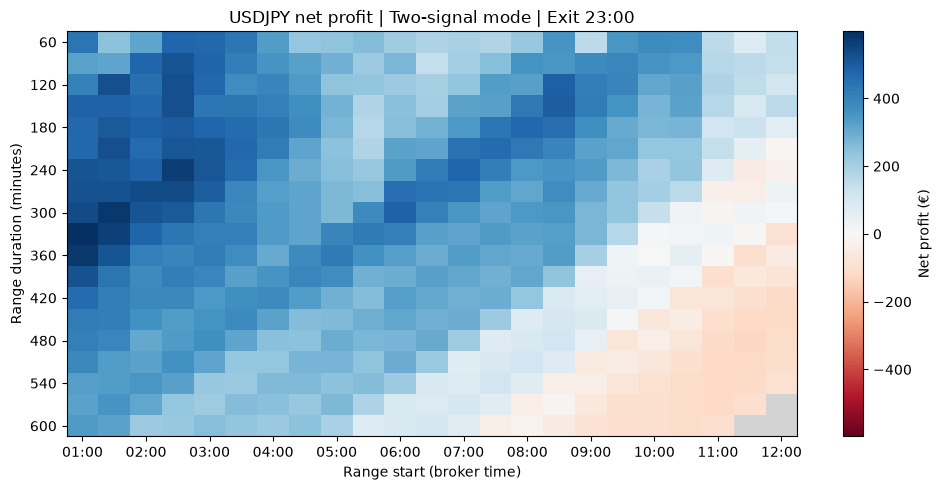

In [8]:
import matplotlib.pyplot as plt

cmap = plt.get_cmap("RdBu").copy()
cmap.set_bad("lightgrey")
limit = profit_grid.abs().max().max()

fig, ax = plt.subplots(figsize=(10, 5))
heatmap = ax.imshow(
    profit_grid,
    cmap=cmap,
    vmin=-limit,
    vmax=limit,
    aspect="auto",
    interpolation="nearest",
)

start_labels = [f"{m // 60:02d}:{m % 60:02d}" for m in profit_grid.columns[::2]]
ax.set_xticks(range(0, profit_grid.shape[1], 2), start_labels)
ax.set_yticks(range(0, profit_grid.shape[0], 2), profit_grid.index[::2])
ax.set_xlabel("Range start (broker time)")
ax.set_ylabel("Range duration (minutes)")
ax.set_title("USDJPY net profit | Two-signal mode | Exit 23:00")
fig.colorbar(heatmap, ax=ax, label="Net profit (€)")
fig.tight_layout()
plt.show()

Each cell represents one setting from the original 30-minute grid. For the 23:00 exit, many early-starting ranges were profitable in the historical sample. Losses cluster among later starts with longer ranges. Grey cells had less than 120 minutes between the range end and the scheduled exit.